In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, class_likelihood_ratios
from sklearn.linear_model import LogisticRegression

In [67]:
df = pd.read_csv(r"C:\Users\felip\OneDrive\Documents\ANN\datasets\bank_marketing\bank-additional\bank-additional-full.csv", sep = ';')
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [68]:
df.info()
df['y'].value_counts(normalize=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

In [69]:
# Basic cleaning

df = df.drop_duplicates()
df = df.drop(columns = 'duration')
df = df.replace('unkown', np.nan)
df.isna().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [70]:
num_cols = df.select_dtypes(include = 'number').columns
cat_cols = df.select_dtypes(include='object').columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
    
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [71]:
# Data preprocessing

X = df.drop(columns = 'y')
X = pd.get_dummies(X, drop_first = True, dtype = int)

y = (df['y'] == 'yes').astype(int).values

X.head()

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,job_blue-collar,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,1,0,0,0,1,0,0,0,1,0
1,57,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,1,0,0,0,1,0,0,0,1,0
2,37,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,1,0,0,0,1,0,0,0,1,0
3,40,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,1,0,0,0,1,0,0,0,1,0
4,56,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,1,0,0,0,1,0,0,0,1,0


In [72]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols] = scaler.transform(X_val[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train.head()

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,job_blue-collar,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
27506,1.632401,-0.203357,0.197112,-0.349305,-0.115904,-0.648967,-0.324618,0.231376,0.398403,0,...,0,1,0,0,0,0,0,0,1,0
20991,0.384367,-0.566537,0.197112,-0.349305,0.838925,-0.227667,0.950131,0.774643,0.844054,1,...,0,0,0,0,0,1,0,0,1,0
34380,-0.863667,-0.566537,0.197112,1.656278,-1.198042,-1.179046,-1.232066,-1.355792,-0.935789,1,...,1,0,0,0,0,1,0,0,0,0
17259,1.248390,-0.203357,0.197112,-0.349305,0.838925,0.590761,-0.475859,0.773491,0.844054,0,...,0,0,0,0,0,0,0,0,1,0
15329,-0.863667,-0.203357,0.197112,-0.349305,0.838925,0.590761,-0.475859,0.770610,0.844054,0,...,0,0,0,0,0,0,0,0,1,0


In [73]:
# Logistic regression as baseline 

log_reg = LogisticRegression(max_iter=5000)
log_reg.fit(X_train, y_train)

lr_probs = log_reg.predict_log_proba(X_test)[:,1]
print(f'LogReg ROC-AUC: {roc_auc_score(y_test, lr_probs):.4f}   AP: {average_precision_score(y_test, lr_probs):.4f}')

LogReg ROC-AUC: 0.8133   AP: 0.4644


In [74]:
# Tensors and data batches

X_train_t = torch.tensor(X_train.values, dtype=torch.float32)
X_val_t = torch.tensor(X_val.values, dtype=torch.float32)
X_test_t = torch.tensor(X_test.values, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1,1)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1,1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1,1)

train_ds = TensorDataset(X_train_t, y_train_t)
val_ds = TensorDataset(X_val_t, y_val_t)
test_ds = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_ds, shuffle=True, batch_size=64)
val_loader = DataLoader(val_ds, shuffle=False, batch_size=256)
test_loader = DataLoader(test_ds, shuffle=False, batch_size=256)

In [75]:
# Network

class Net(nn.Module):
    
    def __init__(self, n_features):
        
        super().__init__()
        
        self.layers = nn.Sequential(
            nn.Linear(n_features, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            #nn.Linear(64, 32),
            #nn.ReLU(),
            #nn.Dropout(0.2),
            
            nn.Linear(16,1)
        )
        
    def forward(self, x):
        
        return self.layers(x)

torch.manual_seed(42)

model = Net(n_features=X_train.shape[1])

print(model)
print(sum(p.numel() for p in model.parameters()))

Net(
  (layers): Sequential(
    (0): Linear(in_features=52, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=16, out_features=1, bias=True)
  )
)
865


In [76]:
n_pos = y_train.sum()
n_neg = len(y_train) - n_pos

pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32)

print('positives: ', n_pos, 'negatives: ', n_neg, 'pos_weight: ', pos_weight.item())

loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

positives:  3247 negatives:  25576 pos_weight:  7.876809597015381


In [ ]:
# Training loop

import copy

n_epochs = 50

train_losses = []
val_losses = []

best_val_loss = float('inf')
best_state = None


for epoch in range(n_epochs):
    
    # train
    model.train()
    running_loss = 0.0
    
    for xb, yb in train_loader:
        
        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()*len(xb)
    
    train_loss = running_loss / len(train_loader.dataset)
    
    # validation
    
    model.eval()
    running_loss = 0.0
    
    with torch.no_grad():
        
        for xb, yb in val_loader:
            
            logits = model(xb)
            loss = loss_fn(logits, yb)
            
            running_loss += loss.item()*len(xb)
    
    val_loss = running_loss / len(val_loader.dataset)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    
    # keep best model
    
    if val_loss < best_val_loss:
        
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
    
    if (epoch+1) % 5 == 0:    
        print(f'Epoch {epoch + 1:2d} | train loss: {train_loss:.4f} | val loss: {val_loss:.4f}')

model.load_state_dict(best_state)

Epoch  5 | train loss: 0.9387 | val loss: 0.9433
Epoch 10 | train loss: 0.9352 | val loss: 0.9416
Epoch 15 | train loss: 0.9341 | val loss: 0.9431


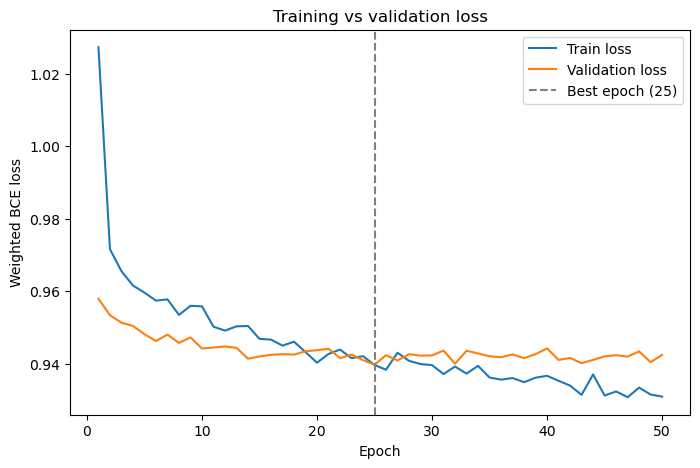

In [78]:
# Plot training and validation loss


epochs = range(1, n_epochs+1)

best_epoch = val_losses.index(min(val_losses)) + 1

plt.figure(figsize=(8,5))

plt.plot(epochs, train_losses, label = 'Train loss')
plt.plot(epochs, val_losses, label = 'Validation loss')

plt.axvline(best_epoch, color = 'gray', linestyle = '--', label = f'Best epoch ({best_epoch})')

plt.xlabel('Epoch')
plt.ylabel('Weighted BCE loss')
plt.title('Training vs validation loss')
plt.legend()
plt.show()


In [79]:
model.eval()

with torch.no_grad():
    test_logits = model(X_test_t)

test_probs = torch.sigmoid(test_logits).numpy().ravel()

In [80]:
test_auc = roc_auc_score(y_test, test_probs)
test_ap = average_precision_score(y_test, test_probs)

print(f'Test ROC-AUC: {test_auc:.4f}')
print(f'Test AP:      {test_ap:.4f}')


Test ROC-AUC: 0.8149
Test AP:      0.4735
